# NinjaPhonetics E2: 4群ベンチマーク音響プロソディ指標の分布解析

- 対象コホート: UK-Native, US-Native, JP-Accented, JP-Mora-Forced (各 n=10)
- 比較指標:
  1. %V (母音占有率 [%])
  2. %C (子音占有率 [%])
  3. nPVI_clipped (30msフロア補正済み正規化母音変動指標)
  4. Schwa Median (弱母音中央値 [ms])
  5. Schwa P75 (弱母音第3四分位数 [ms])
  6. Stressed / Unstressed 平均長比

In [9]:
!python generate_benchmarks.py



🎬 Processing Sentence: S1_stress
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S2_clusters
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S3_connected
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

Generation complete. Total audio files: 120. Manifest: benchmarks/manifest.json


In [11]:

!python evaluate_benchmarks.py

Processing alignment for 120 items...
  [OK] [S1_stress] UK-Native_01_ArcherConver_male.wav | %V:  45.9% | P75:  46.8ms
  [OK] [S1_stress] UK-Native_02_BlondieConve_female.wav | %V:  47.0% | P75:  51.0ms
  [OK] [S1_stress] UK-Native_03_LucyFreshCas_female.wav | %V:  48.2% | P75:  57.5ms
  [OK] [S1_stress] UK-Native_04_Leon_male.wav       | %V:  46.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_05_Archer_male.wav     | %V:  48.6% | P75:  56.9ms
  [OK] [S1_stress] UK-Native_06_Tom_male.wav        | %V:  47.0% | P75:  50.8ms
  [OK] [S1_stress] UK-Native_07_FraserFintec_male.wav | %V:  44.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_08_NathanielNat_male.wav | %V:  47.7% | P75:  63.7ms
  [OK] [S1_stress] UK-Native_09_TylerPleasan_male.wav | %V:  45.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_10_TrinityXConv_female.wav | %V:  46.9% | P75:  50.9ms
  [OK] [S1_stress] US-Native_01_RogerLaidBac_male.wav | %V:  46.2% | P75:  59.2ms
  [OK] [S1_stress] US-Native_02_WillRelaxedO_male.wav | %V: 

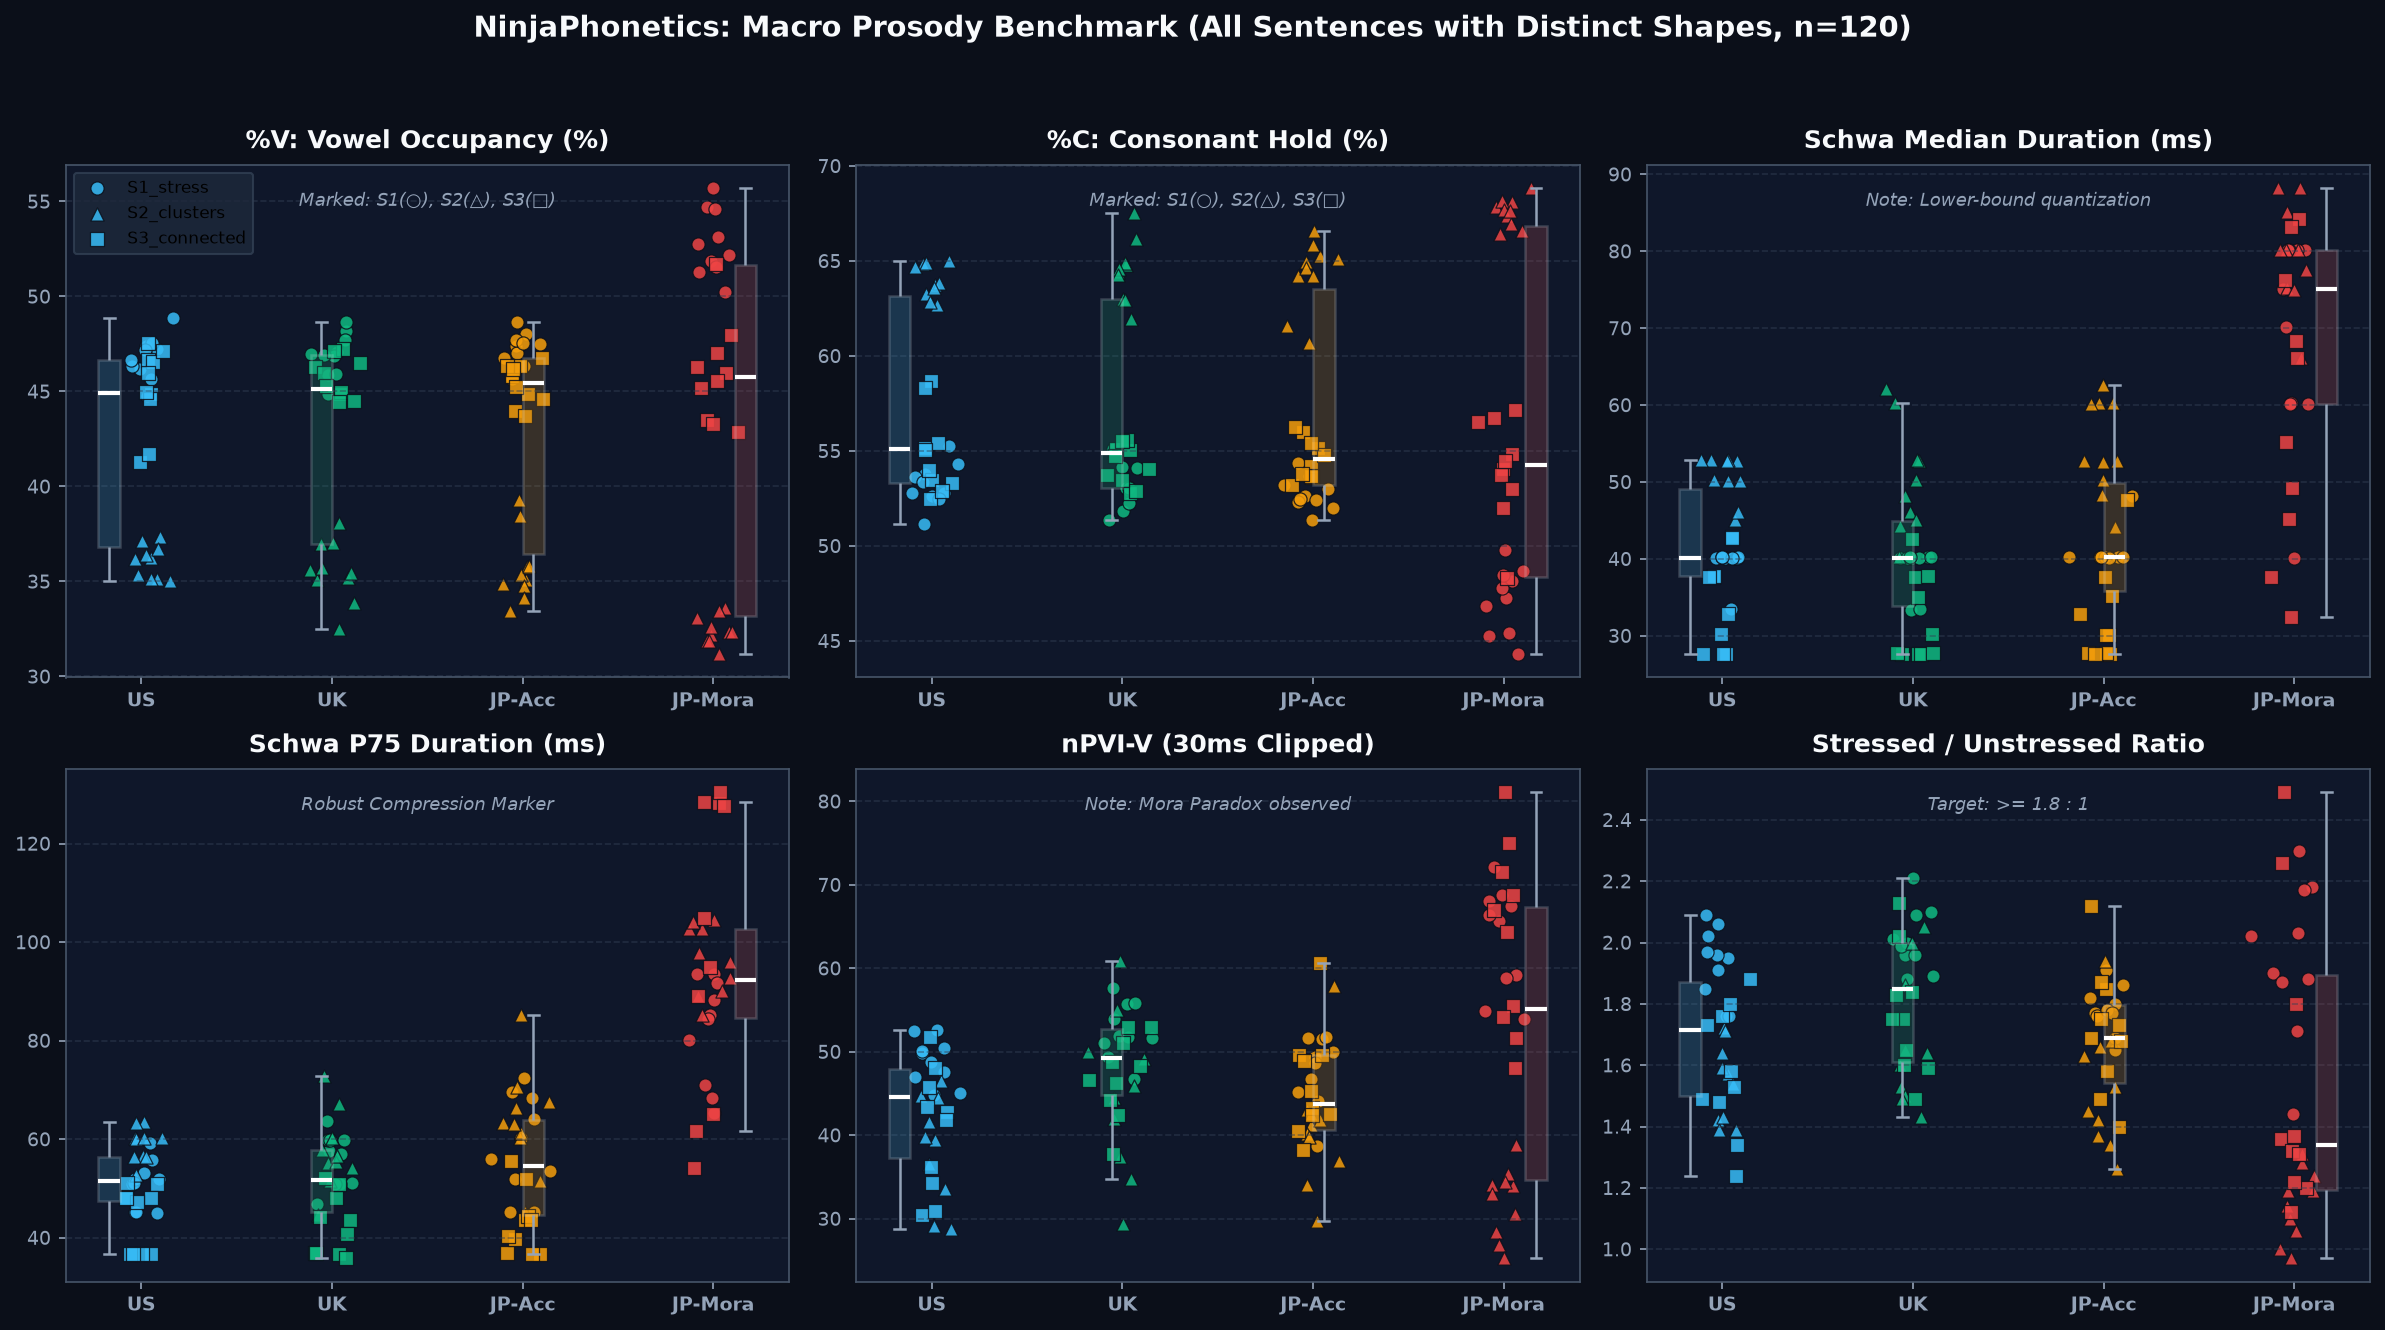

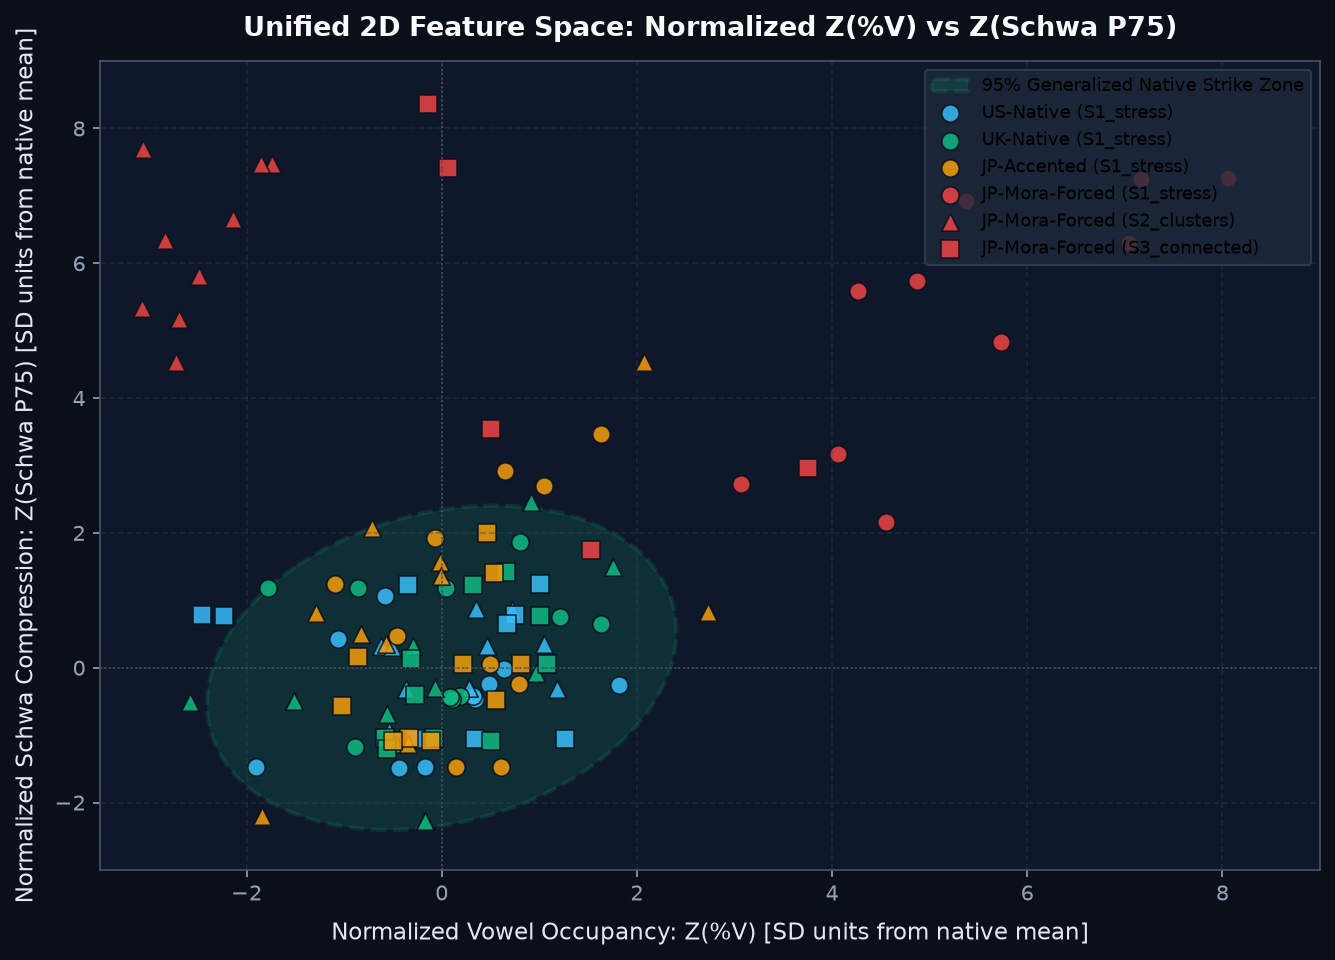

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns

# 1. データの読み込み
df = pd.read_csv("benchmarks/benchmark_results_all.csv")
cohort_order = ["US-Native", "UK-Native", "JP-Accented", "JP-Mora-Forced"]
palette = {
    "US-Native": "#38BDF8",       # スカイブルー
    "UK-Native": "#10B981",       # エメラルドグリーン
    "JP-Accented": "#F59E0B",     # アンバー
    "JP-Mora-Forced": "#EF4444"   # レッド
}
df['cohort'] = pd.Categorical(df['cohort'], categories=cohort_order, ordered=True)

# 文章ごとのマーカー形状定義
sentence_markers = {
    "S1_stress": "o",       # 丸
    "S2_clusters": "^",     # 三角
    "S3_connected": "s"     # 四角
}

# %%
# 2. ネイティブ基準による文章正規化（Z-score の算出）
native_mask = df['cohort'].isin(["US-Native", "UK-Native"])

# 各文章・各指標ごとのネイティブ平均・標準偏差を辞書化
norm_cols = ["pct_v", "pct_c", "schwa_p75_ms"]
df_norm = df.copy()

for s_key in df['sentence_key'].unique():
    s_nat = df[(df['sentence_key'] == s_key) & native_mask]
    for col in norm_cols:
        m = s_nat[col].mean()
        s = s_nat[col].std(ddof=1)
        # Z-score 化
        df_norm.loc[df['sentence_key'] == s_key, f"z_{col}"] = (df.loc[df['sentence_key'] == s_key, col] - m) / s

# %%
# 3. 6大指標 Boxplot: マーカー形状を文章別に分離して重ね合わせ
fig, axes = plt.subplots(2, 3, figsize=(16, 9), dpi=150)
fig.patch.set_facecolor('#0B0F19')
axes = axes.flatten()

metrics_to_plot = [
    ("pct_v", "%V: Vowel Occupancy (%)", "Marked: S1(○), S2(△), S3(□)"),
    ("pct_c", "%C: Consonant Hold (%)", "Marked: S1(○), S2(△), S3(□)"),
    ("schwa_median_ms", "Schwa Median Duration (ms)", "Note: Lower-bound quantization"),
    ("schwa_p75_ms", "Schwa P75 Duration (ms)", "Robust Compression Marker"),
    ("npvi_clipped", "nPVI-V (30ms Clipped)", "Note: Mora Paradox observed"),
    ("s_u_ratio_mean", "Stressed / Unstressed Ratio", "Target: >= 1.8 : 1")
]

for idx, (col, title, subtitle) in enumerate(metrics_to_plot):
    ax = axes[idx]
    ax.set_facecolor('#0F172A')
    
    # 箱ひげ図
    sns.boxplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        width=0.45,
        boxprops=dict(alpha=0.20, edgecolor='#E2E8F0', linewidth=1.2),
        whiskerprops=dict(color='#94A3B8', linewidth=1.2),
        capprops=dict(color='#94A3B8', linewidth=1.2),
        medianprops=dict(color='#FFFFFF', linewidth=2.0),
        showfliers=False
    )
    
    # 文章ごとに異なるマーカーで散布（Jitter付き）
    for s_key, marker_sym in sentence_markers.items():
        sub = df[df['sentence_key'] == s_key]
        for c_idx, c_name in enumerate(cohort_order):
            c_vals = sub[sub['cohort'] == c_name][col]
            # 各コホートのX座標に微小なランダムジッターを付与
            jitter = np.random.normal(0, 0.06, size=len(c_vals))
            ax.scatter(
                c_idx + jitter, c_vals,
                color=palette[c_name],
                marker=marker_sym,
                s=40, alpha=0.85, edgecolors='#0B0F19', linewidth=0.6,
                label=s_key if (idx == 0 and c_idx == 0) else None
            )
            
    ax.set_title(title, fontsize=12, fontweight='bold', color='#F8FAFC', pad=8)
    ax.text(0.5, 0.92, subtitle, transform=ax.transAxes, ha='center',
            fontsize=8.5, color='#94A3B8', style='italic')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(colors='#94A3B8', labelsize=9)
    ax.grid(True, axis='y')
    ax.set_xticks(range(len(cohort_order)))
    ax.set_xticklabels(["US", "UK", "JP-Acc", "JP-Mora"], rotation=0, fontweight='bold')

axes[0].legend(frameon=True, facecolor='#1E293B', edgecolor='#334155', fontsize=8, loc='upper left')
plt.suptitle("NinjaPhonetics: Macro Prosody Benchmark (All Sentences with Distinct Shapes, n=120)", 
             fontsize=14, fontweight='bold', color='#F8FAFC', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("benchmarks/prosody_distribution_shapes.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

# %%
# 4. 正規化後の統合2Dストライクゾーン（Z_%V vs Z_Schwa_P75）
def draw_confidence_ellipse(x, y, ax, n_std=2.447, facecolor='#10B981', alpha=0.15, **kwargs):
    x, y = np.asarray(x), np.asarray(y)
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 0))
    ellipse = Ellipse(xy=(np.mean(x), np.mean(y)), width=width, height=height,
                      angle=theta, facecolor=facecolor, alpha=alpha, **kwargs)
    return ax.add_patch(ellipse)

fig, ax = plt.subplots(figsize=(9, 6.5), dpi=150)
fig.patch.set_facecolor('#0B0F19')
ax.set_facecolor('#0F172A')

# ネイティブ全体の 95% 正規化ストライクゾーン
nat_norm = df_norm[df_norm['cohort'].isin(["US-Native", "UK-Native"])]
draw_confidence_ellipse(
    nat_norm['z_pct_v'], nat_norm['z_schwa_p75_ms'], ax,
    n_std=2.447, facecolor='#10B981', alpha=0.15,
    edgecolor='#10B981', linestyle='--', linewidth=2.0,
    label='95% Generalized Native Strike Zone'
)

# 各コホート・各文章のプロット
for c_name in cohort_order:
    for s_key, marker_sym in sentence_markers.items():
        sub = df_norm[(df_norm['cohort'] == c_name) & (df_norm['sentence_key'] == s_key)]
        ax.scatter(
            sub['z_pct_v'], sub['z_schwa_p75_ms'],
            color=palette[c_name], marker=marker_sym,
            s=70, alpha=0.85, edgecolors='#0B0F19', linewidth=0.8,
            label=f"{c_name} ({s_key})" if c_name == "JP-Mora-Forced" or s_key == "S1_stress" else None
        )

ax.axhline(0, color='#475569', linestyle=':', linewidth=0.8)
ax.axvline(0, color='#475569', linestyle=':', linewidth=0.8)

ax.set_title("Unified 2D Feature Space: Normalized Z(%V) vs Z(Schwa P75)", 
             fontsize=13, fontweight='bold', color='#F8FAFC', pad=12)
ax.set_xlabel("Normalized Vowel Occupancy: Z(%V) [SD units from native mean]", fontsize=11, color='#E2E8F0', labelpad=8)
ax.set_ylabel("Normalized Schwa Compression: Z(Schwa P75) [SD units from native mean]", fontsize=11, color='#E2E8F0', labelpad=8)

ax.set_xlim(-3.5, 9.0)
ax.set_ylim(-3.0, 9.0)
ax.tick_params(colors='#94A3B8')
ax.grid(True, linestyle='--', alpha=0.4, color='#334155')

handles, labels = ax.get_legend_handles_labels()
# 重複ラベルの整理
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), frameon=True, facecolor='#1E293B', edgecolor='#334155', fontsize=8.5, loc='upper right')

plt.tight_layout()
plt.savefig("benchmarks/prosody_unified_strike_zone.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()